In [256]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import math

In [257]:
df = pd.read_csv(
    "train_FD001.txt",
    sep=r"\s+",
    header=None
)

print(df)

        0    1       2       3      4       5       6        7        8   \
0        1    1 -0.0007 -0.0004  100.0  518.67  641.82  1589.70  1400.60   
1        1    2  0.0019 -0.0003  100.0  518.67  642.15  1591.82  1403.14   
2        1    3 -0.0043  0.0003  100.0  518.67  642.35  1587.99  1404.20   
3        1    4  0.0007  0.0000  100.0  518.67  642.35  1582.79  1401.87   
4        1    5 -0.0019 -0.0002  100.0  518.67  642.37  1582.85  1406.22   
...    ...  ...     ...     ...    ...     ...     ...      ...      ...   
20626  100  196 -0.0004 -0.0003  100.0  518.67  643.49  1597.98  1428.63   
20627  100  197 -0.0016 -0.0005  100.0  518.67  643.54  1604.50  1433.58   
20628  100  198  0.0004  0.0000  100.0  518.67  643.42  1602.46  1428.18   
20629  100  199 -0.0011  0.0003  100.0  518.67  643.23  1605.26  1426.53   
20630  100  200 -0.0032 -0.0005  100.0  518.67  643.85  1600.38  1432.14   

          9   ...      16       17       18      19    20   21    22     23  \
0      1

In [258]:
columns = (
    ["unit", "cycle", "setting1", "setting2", "setting3"]
    + [f"sensor{i}" for i in range(1, 22)]
)

df.columns = columns

print(df)

       unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0         1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1         1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2         1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3         1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4         1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   
...     ...    ...       ...       ...       ...      ...      ...      ...   
20626   100    196   -0.0004   -0.0003     100.0   518.67   643.49  1597.98   
20627   100    197   -0.0016   -0.0005     100.0   518.67   643.54  1604.50   
20628   100    198    0.0004    0.0000     100.0   518.67   643.42  1602.46   
20629   100    199   -0.0011    0.0003     100.0   518.67   643.23  1605.26   
20630   100    200   -0.0032   -0.0005     100.0   518.67   643.85  1600.38   

       sensor4  sensor5  ...  sensor12  sensor13  s

In [259]:
engine1= df[df["unit"] == 1]
engine1 = engine1.drop(engine1.columns[15:17], axis =1)
print(engine1)

     unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0       1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1       1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2       1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3       1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4       1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   
..    ...    ...       ...       ...       ...      ...      ...      ...   
187     1    188   -0.0067    0.0003     100.0   518.67   643.75  1602.38   
188     1    189   -0.0006    0.0002     100.0   518.67   644.18  1596.17   
189     1    190   -0.0027    0.0001     100.0   518.67   643.64  1599.22   
190     1    191   -0.0000   -0.0004     100.0   518.67   643.34  1602.36   
191     1    192    0.0009   -0.0000     100.0   518.67   643.54  1601.41   

     sensor4  sensor5  ...  sensor10  sensor13  sensor14  sensor15  sensor1

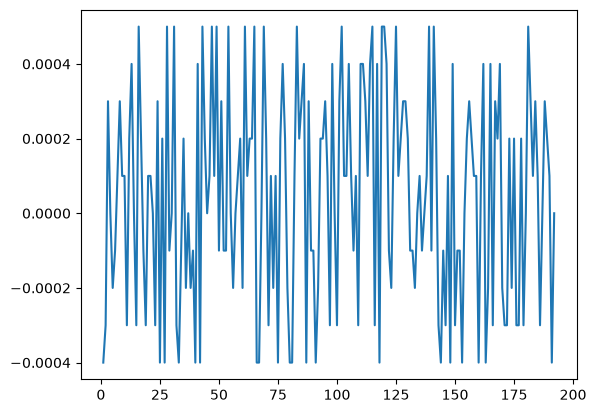

In [260]:
plt.plot(engine1['cycle'], engine1['setting2'])

In [261]:
max_cycle = df.groupby("unit")["cycle"].max()

In [262]:
max_cycle = df["unit"].map(max_cycle)

In [263]:
df['RUL'] = max_cycle-df['cycle']
df

,unit,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor13,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735,4
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594,3
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333,2
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640,1


In [264]:
df.groupby("unit")["RUL"].min()

unit
1      0
2      0
3      0
4      0
5      0
      ..
96     0
97     0
98     0
99     0
100    0
Name: RUL, Length: 100, dtype: int64

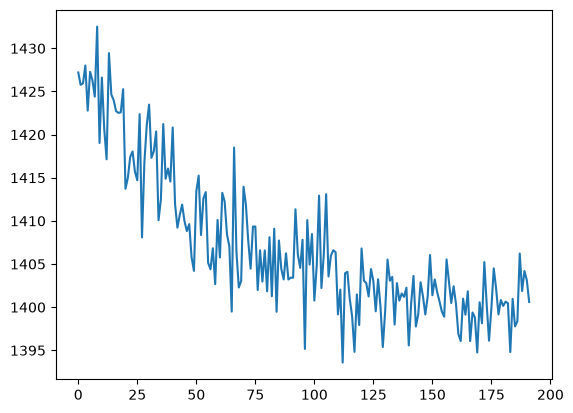

In [265]:
engine1 = df[df["unit"] == 1]

plt.plot(engine1["RUL"], engine1["sensor4"])

In [266]:
corr = df.corr()["RUL"].sort_values()

print(corr)

cycle      -0.736241
sensor11   -0.696228
sensor4    -0.678948
sensor15   -0.642667
sensor2    -0.606484
sensor17   -0.606154
sensor3    -0.584520
sensor8    -0.563968
sensor13   -0.562569
sensor9    -0.390102
sensor14   -0.306769
sensor6    -0.128348
setting1   -0.003198
setting2   -0.001948
unit        0.078753
sensor20    0.629428
sensor21    0.635662
sensor7     0.657223
sensor12    0.671983
RUL         1.000000
setting3         NaN
sensor1          NaN
sensor5          NaN
sensor10         NaN
sensor16         NaN
sensor18         NaN
sensor19         NaN
Name: RUL, dtype: float64


In [267]:
X = df.iloc[:, :-1]
X = df.drop(columns=["unit","cycle", "RUL"])
print(X)
y = df['RUL']
print(y)

       setting1  setting2  setting3  sensor1  sensor2  sensor3  sensor4  \
0       -0.0007   -0.0004     100.0   518.67   641.82  1589.70  1400.60   
1        0.0019   -0.0003     100.0   518.67   642.15  1591.82  1403.14   
2       -0.0043    0.0003     100.0   518.67   642.35  1587.99  1404.20   
3        0.0007    0.0000     100.0   518.67   642.35  1582.79  1401.87   
4       -0.0019   -0.0002     100.0   518.67   642.37  1582.85  1406.22   
...         ...       ...       ...      ...      ...      ...      ...   
20626   -0.0004   -0.0003     100.0   518.67   643.49  1597.98  1428.63   
20627   -0.0016   -0.0005     100.0   518.67   643.54  1604.50  1433.58   
20628    0.0004    0.0000     100.0   518.67   643.42  1602.46  1428.18   
20629   -0.0011    0.0003     100.0   518.67   643.23  1605.26  1426.53   
20630   -0.0032   -0.0005     100.0   518.67   643.85  1600.38  1432.14   

       sensor5  sensor6  sensor7  ...  sensor12  sensor13  sensor14  sensor15  \
0        14.62    

In [268]:
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)
train_idx, val_idx = next(
    gss.split(X, y, groups=df["unit"])
)

X_train = X.iloc[train_idx]
X_val   = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val   = y.iloc[val_idx]

In [269]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_val)

In [270]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 26.005948402948405
RMSE: 35.5670169603039


In [271]:
X = df.iloc[:, :-1]
X = df.drop(columns=["unit", "RUL"])
y = df['RUL']

from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)
train_idx, val_idx = next(
    gss.split(X, y, groups=df["unit"])
)

X_train = X.iloc[train_idx]
X_val   = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val   = y.iloc[val_idx]

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_val)

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 24.01100982800983
RMSE: 31.702960859329167


GIVING CYCLES DID NOT HELP

In [272]:
features = df.drop(columns=["unit", "cycle", "RUL"])
X = []
y = []
groups = []
window_size=20

for unit in df["unit"].unique():

    engine = df[df["unit"] == unit]

    data = engine[features.columns].values
    rul = engine["RUL"].values

    for i in range(len(engine) - window_size + 1):

        window = data[i:i + window_size]

        X.append(window.reshape(-1))

        y.append(rul[i + window_size - 1])

        groups.append(unit)

In [273]:
X = np.array(X)
y = np.array(y)

groups = np.array(groups)

In [274]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(X, y, groups=groups)
)
X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

In [275]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_val)

In [276]:
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 21.914501355013552
RMSE: 30.287113312734647


GIVING THE DATA FOR LAST 20 SENSORS DIDNT MUCH EITHER

THIS SHOWS USING RANDOM FOREST WONT HELP MUCH